# Module 03 · Mạch op-amp cơ bản (Floyd chương 13)

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Hysteresis
**Câu hỏi:** Hình 13–61 (R1 = 47 kΩ, R2 = 18 kΩ, Vout(max) = ±10 V) có ngưỡng nào?

VUTP = 2.77 V, VLTP = -2.77 V, VHYS = 5.54 V


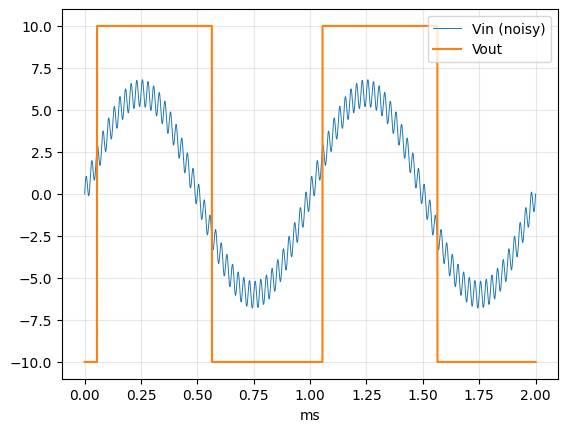

transitions: 4


In [2]:
R1, R2, Vm = 47, 18, 10
UT = R2/(R1+R2)*Vm
print(f"VUTP = {UT:.2f} V, VLTP = {-UT:.2f} V, VHYS = {2*UT:.2f} V")
t = np.linspace(0, 2e-3, 4000); vin = 6*np.sin(2*np.pi*1e3*t) + 0.8*np.sin(2*np.pi*40e3*t)
out = np.zeros_like(t); s = -Vm
for k, v in enumerate(vin):
    if s < 0 and v > UT: s = Vm
    elif s > 0 and v < -UT: s = -Vm
    out[k] = s
plt.plot(t*1e3, vin, lw=.7, label="Vin (noisy)"); plt.plot(t*1e3, out, label="Vout"); plt.legend(); plt.grid(alpha=.3); plt.xlabel("ms"); plt.show()
print("transitions:", int(np.sum(np.diff(out) != 0)))

**Nhận xét:** VUTP = 2.77 V đúng đáp án sách (±2,77 V). Dù nhiễu 40 kHz biên độ 0,8 V chồng lên tín hiệu, ngõ ra chỉ chuyển 4 lần trong 2 chu kỳ nhờ hysteresis 5.54 V.

## 2. Mạch cộng và cộng có trọng số

In [3]:
print("Prob 9b:", -22/10*(0.1+1+0.5), "V")
Rf=10; R=[10,33,91,180]; V=[2,3,3,6]
vo=-sum(Rf/r*v for r,v in zip(R,V)); print(f"Prob 13: VOUT = {vo:.3f} V, If = {abs(vo)/10e3*1e6:.0f} uA")
print("Prob 14 Ri (kOhm):", [100/w for w in (1,2,4,8,16,32)])

Prob 9b: -3.5200000000000005 V
Prob 13: VOUT = -3.572 V, If = 357 uA
Prob 14 Ri (kOhm): [100.0, 50.0, 25.0, 12.5, 6.25, 3.125]


**Nhận xét:** VOUT bài 9b = −3,52 V; bài 13 cho −3.572 V (dòng 357 μA); sáu điện trở bài 14 giảm một nửa liên tiếp từ 100 kΩ đến 3,125 kΩ.

## 3. Tích phân: bước nhảy và sóng vuông

Prob 15: dVout/dt = -4058 V/s = -4.06 V/ms


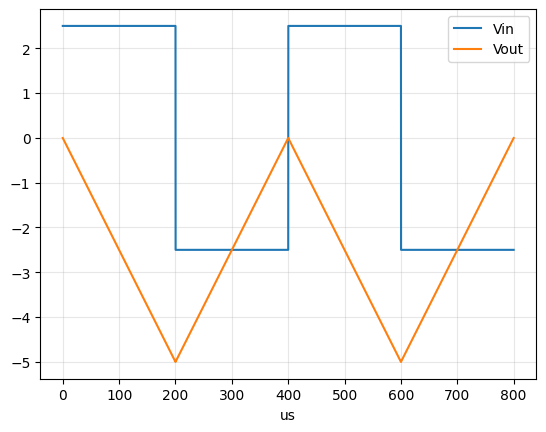

peak-to-peak after 200 us: 5.00 V


In [4]:
R, C = 56e3, 0.022e-6
print(f"Prob 15: dVout/dt = {-5/(R*C):.0f} V/s = {-5/(R*C)/1e3:.2f} V/ms")
R, C, dt = 10e3, 0.01e-6, 1e-7
t = np.arange(0, 800e-6, dt); vin = np.where((t//200e-6) % 2 == 0, 2.5, -2.5)
vo = -np.cumsum(vin)*dt/(R*C)
plt.plot(t*1e6, vin, label="Vin"); plt.plot(t*1e6, vo, label="Vout"); plt.legend(); plt.xlabel("us"); plt.grid(alpha=.3); plt.show()
print(f"peak-to-peak after 200 us: {abs(vo[int(200e-6/dt)-1]):.2f} V")

**Nhận xét:** Tốc độ bài 15 là −4058 V/s (−4.06 V/ms). Với 2,5 V, 10 kΩ, 0,01 μF, đường dốc đạt 5 V sau 200 μs — đúng Hình 13–35(b).

## 4. Vi phân: tam giác → vuông

Prob 18: slope = 4000 V/s, |Vout| = 2.82 V


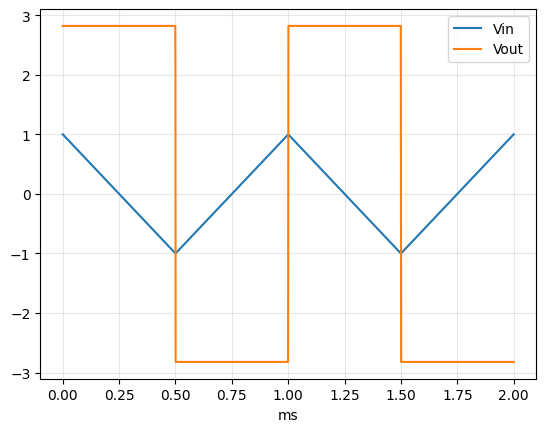

In [5]:
Rf, C, vpp, T = 15e3, 0.047e-6, 2, 1e-3
slope = vpp/(T/2); A = Rf*C*slope
print(f"Prob 18: slope = {slope:.0f} V/s, |Vout| = {A:.2f} V")
t = np.linspace(0, 2*T, 4000); tri = vpp/2*(2*np.abs(2*((t/T)%1)-1)-1)
d = -Rf*C*np.gradient(tri, t); plt.plot(t*1e3, tri, label="Vin"); plt.plot(t*1e3, d, label="Vout"); plt.legend(); plt.grid(alpha=.3); plt.xlabel("ms"); plt.show()

**Nhận xét:** |Vout| = 2.82 V, ngõ ra là sóng vuông ±2.82 V ngược dấu với độ dốc của ngõ vào.